# Dataset exploration

This notebook profiles the locally available SQuAD 2.0 training data for extractive question answering. Each analysis step is kept in a separate cell so the workflow is easy to run, inspect, and extend.

## 1. Load the dataset

In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATASET_PATH = Path("data/raw/squad_v2/train/0000.parquet")
for candidate_root in (Path.cwd(), *Path.cwd().parents):
    candidate_path = candidate_root / DATASET_PATH
    if candidate_path.is_file():
        DATASET_PATH = candidate_path
        
        break
else:
    raise FileNotFoundError(
        f"Could not find {DATASET_PATH} from {Path.cwd()} or its parent directories."
    )

df = pd.read_parquet(DATASET_PATH)
print(f"Loaded: {DATASET_PATH}")
print(f"Rows: {len(df):,} | Columns: {len(df.columns)}")

Loaded: /Users/vaibhav/Documents/Projects/Domain-Adaptive-and-Robustness-Aware-Question-Answering-/data/raw/squad_v2/train/0000.parquet
Rows: 130,319 | Columns: 5


## 2. Inspect schema and sample records

In [9]:
display(df.head())
print("\nColumn types:")
display(df.dtypes.to_frame("dtype"))
print("\nMemory usage:")
print(f"{df.memory_usage(deep=True).sum() / 1024**2:.2f} MiB")

,id,title,context,question,answers
0,56be85543aeaaa14008c9063,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,When did Beyonce start becoming popular?,"{'text': ['in the late 1990s'], 'answer_start'..."
1,56be85543aeaaa14008c9065,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,What areas did Beyonce compete in when she was...,"{'text': ['singing and dancing'], 'answer_star..."
2,56be85543aeaaa14008c9066,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,When did Beyonce leave Destiny's Child and bec...,"{'text': ['2003'], 'answer_start': [526]}"
3,56bf6b0f3aeaaa14008c9601,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,In what city and state did Beyonce grow up?,"{'text': ['Houston, Texas'], 'answer_start': [..."
4,56bf6b0f3aeaaa14008c9602,Beyoncé,Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ b...,In which decade did Beyonce become famous?,"{'text': ['late 1990s'], 'answer_start': [276]}"



Column types:


,dtype
id,str
title,str
context,str
question,str
answers,object



Memory usage:
133.85 MiB


## 3. Check missing values and duplicate records

In [10]:
quality_summary = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.drop(columns="answers").nunique(dropna=False).reindex(df.columns),
})
display(quality_summary)
print(f"Duplicate rows (excluding nested answers): {df.drop(columns='answers').duplicated().sum():,}")
print(f"Duplicate question IDs: {df['id'].duplicated().sum():,}")

,missing_values,missing_percent,unique_values
id,0,0.0,130319.0
title,0,0.0,442.0
context,0,0.0,19029.0
question,0,0.0,130217.0
answers,0,0.0,NaN


Duplicate rows (excluding nested answers): 0
Duplicate question IDs: 0


## 4. Measure answerability

,count,percent
label,,
Answerable,86821,66.62
Unanswerable,43498,33.38


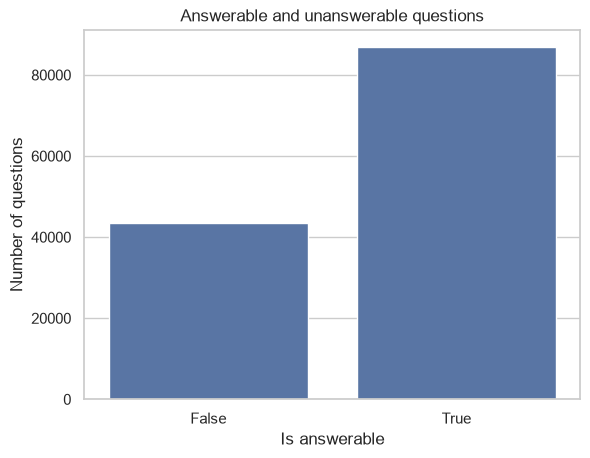

In [11]:
def answer_texts(answer_record):
    """Return answer strings from a SQuAD-style answers record."""
    if not isinstance(answer_record, dict):
        return []
    return list(answer_record.get("text", []))


df["answer_texts"] = df["answers"].map(answer_texts)
df["is_answerable"] = df["answer_texts"].map(bool)

answerability = (
    df["is_answerable"]
    .value_counts()
    .rename(index={True: "Answerable", False: "Unanswerable"})
    .rename_axis("label")
    .to_frame("count")
)
answerability["percent"] = (answerability["count"] / len(df) * 100).round(2)
display(answerability)

sns.countplot(data=df, x="is_answerable")
plt.title("Answerable and unanswerable questions")
plt.xlabel("Is answerable")
plt.ylabel("Number of questions")
plt.show()

## 5. Explore contexts, questions, and answer lengths

In [12]:
df["context_words"] = df["context"].str.split().str.len()
df["question_words"] = df["question"].str.split().str.len()
df["context_chars"] = df["context"].str.len()
df["question_chars"] = df["question"].str.len()
df["answer_words"] = df["answer_texts"].map(
    lambda answers: len(answers[0].split()) if answers else 0
)
df["answer_chars"] = df["answer_texts"].map(
    lambda answers: len(answers[0]) if answers else 0
)

length_summary = df[
    ["context_words", "question_words", "answer_words", "context_chars", "question_chars", "answer_chars"]
].describe().T.round(2)
display(length_summary)


,count,mean,std,min,25%,50%,75%,max
context_words,130319.0,119.61,49.40,20.0,89.0,110.0,141.0,653.0
question_words,130319.0,9.89,3.42,1.0,7.0,9.0,12.0,40.0
answer_words,130319.0,2.11,3.14,0.0,0.0,1.0,3.0,43.0
context_chars,130319.0,754.57,307.62,151.0,561.0,692.0,891.0,3706.0
question_chars,130319.0,58.51,73.76,1.0,44.0,55.0,69.0,25651.0
answer_chars,130319.0,13.42,20.02,0.0,0.0,7.0,17.0,239.0


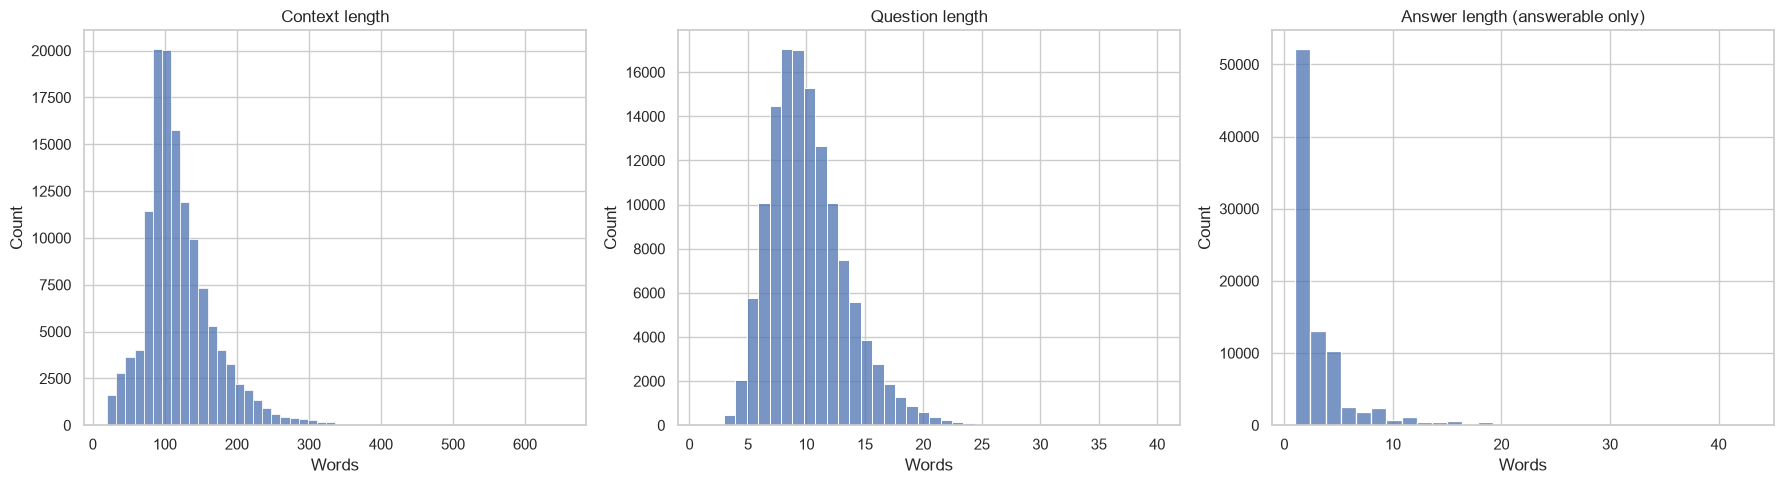

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(df["context_words"], bins=50, ax=axes[0])
axes[0].set_title("Context length")
axes[0].set_xlabel("Words")
sns.histplot(df["question_words"], bins=40, ax=axes[1])
axes[1].set_title("Question length")
axes[1].set_xlabel("Words")
sns.histplot(df.loc[df["is_answerable"], "answer_words"], bins=30, ax=axes[2])
axes[2].set_title("Answer length (answerable only)")
axes[2].set_xlabel("Words")
plt.tight_layout()
plt.show()

## 6. Explore titles and question distribution

In [14]:
title_summary = (
    df.groupby("title")
    .agg(
        questions=("id", "size"),
        contexts=("context", "nunique"),
        answerable_rate=("is_answerable", "mean"),
    )
    .sort_values("questions", ascending=False)
)
title_summary["answerable_rate"] = (title_summary["answerable_rate"] * 100).round(2)
print(f"Unique titles: {df['title'].nunique():,}")
display(title_summary.head(15))

question_starts = (
    df["question"].str.extract(r"^(\w+)", expand=False).str.lower().value_counts().head(15)
)
display(question_starts.rename("count").to_frame())

Unique titles: 442


,questions,contexts,answerable_rate
title,,,
Queen_Victoria,883,42,76.67
New_York_City,817,148,100.00
American_Idol,790,127,100.00
Beyoncé,753,66,100.00
Frédéric_Chopin,697,82,100.00
Buddhism,610,149,100.00
Pharmaceutical_industry,586,44,62.63
"New_Haven,_Connecticut",582,66,100.00
Premier_League,551,40,64.79


,count
question,
what,58433
who,12426
how,11424
when,7725
in,6454
which,5624
where,4621
the,3090
why,1834


## 7. Validate answer offsets against the context

In [15]:
def answer_offset_is_valid(row):
    answers = row["answers"]
    if not isinstance(answers, dict):
        return True
    texts = answers.get("text", [])
    starts = answers.get("answer_start", [])
    if len(texts) == 0:
        return True
    return all(
        0 <= start <= len(row["context"])
        and row["context"][start:start + len(text)] == text
        for text, start in zip(texts, starts)
    )


offset_valid = df.apply(answer_offset_is_valid, axis=1)
print(f"Valid answer offsets: {offset_valid.sum():,}/{len(df):,}")
print(f"Invalid answer offsets: {(~offset_valid).sum():,}")
assert offset_valid.all(), "At least one answer span does not match its context."


Valid answer offsets: 130,319/130,319
Invalid answer offsets: 0


## 8. Inspect representative examples

In [16]:
columns_to_show = ["title", "question", "context", "answer_texts", "is_answerable"]
display(df.loc[df["is_answerable"], columns_to_show].sample(3, random_state=42))
display(df.loc[~df["is_answerable"], columns_to_show].sample(3, random_state=42))

,title,question,context,answer_texts,is_answerable
27145,Wood,"After cellulose, what component is most plenti...","Aside from water, wood has three main componen...",[hemicellulose],True
125025,The_Bronx,How much of the Bronx's vote in 1916 did Hughe...,"Since then, the Bronx has always supported the...",[42.6%],True
13110,Hunter-gatherer,When did Homo sapiens begin using subsistence ...,Hunting and gathering was presumably the subsi...,[0.2 million years ago],True


,title,question,context,answer_texts,is_answerable
32915,Orthodox_Judaism,Which country have the Haredi and the Hasidic ...,"On the other hand, Orthodox Jews subscribing t...",[],False
19750,Tristan_da_Cunha,Who is the UK an overseas territory of?,The 1961 volcanic eruption destroyed the Trist...,[],False
113125,Muslim_world,What did Edward Pococke the Younger translate ...,"A Latin translation of Ibn Tufail's work, Phil...",[],False


## Findings to carry into preprocessing

- The dataset contains both answerable and unanswerable questions, so preprocessing must preserve that label.
- Answer spans should be checked after any context transformation because training labels depend on character offsets.
- Context and question length distributions should guide tokenizer truncation and stride settings.
- The title distribution is uneven; title-aware splits or grouped analysis may be useful when comparing domains.